# 07. Final experiments: augmentation, demographics, final model

Analysis of the runs of `scripts/submit_experiments.sh` and `scripts/submit_final.sh` (Deucalion). **Nothing is trained here**:
every number is recomputed from the saved out-of-fold predictions (`results/<run>/oof.csv`), the training
histories (`history_fold*.csv`) and the stacking outputs (`results/stack_<model>/`).

| question | runs (4 seeds each: 42, 1, 2, 3) |
|---|---|
| reference (audio, augmentation on) | `cnn, cnn_s1..s3`, `rnn, rnn_s1..s3` |
| A. what does augmentation give? | `{cnn,rnn}_noaug_s*` (`--no-spec-augment --no-random-crop`) |
| B. demographics from the start (early fusion) | `{cnn,rnn}_demo_s*` (`--demo age height`, augmentation on) |
| B. demographics at the end (stacking) | `stack_{cnn,rnn}`: logistic regression on the reference 4-seed ensemble |
| D. submitted model (trained with the test fold) | `rnn_final_s*` (`--include-test`) |

Evaluation as in the rest of the project: patient-level weighted accuracy (WA, 5/3/1), thresholds tuned nested
over the 5 CV folds (753 patients), adoption rule **+0.02 WA and better in ≥ 4/5 folds**. The test fold −1 is not used.

In [1]:
import json, os, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

while not Path('src').is_dir():  # run from the repository root
    os.chdir('..')
from src.compare_runs import evaluate
from src.evaluate import tune_thresholds
from src.evaluate import load_oof, patient_scores, RESULTS_DIR
from sklearn.metrics import roc_auc_score
from src.data import CLASSES

FIG = RESULTS_DIR / 'final_experiments'; FIG.mkdir(parents=True, exist_ok=True)
windows = pd.read_csv('data/processed/windows.csv')
BLUE, ORANGE, AQUA, GREY, INK = '#257de0', '#f47230', '#00b894', '#b0b0b0', '#191919'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#666666',
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'axes.axisbelow': True, 'font.size': 10})

def group(model, kind):
    '''The 4 seeds of a group. The reference runs are cnn, cnn_s1.. (seed 42 has no suffix).'''
    return [f'{model}{s}' for s in ['', '_s1', '_s2', '_s3']] if kind == 'ref' else \
           [f'{model}_{kind}_s{s}' for s in [42, 1, 2, 3]]

def ensemble(names):
    '''Mean of the out-of-fold window probabilities of several runs -> same evaluation as one run.'''
    ps = [load_oof(n) for n in names]
    assert all(np.array_equal(ps[0][0], i) for i, _ in ps)
    return evaluate(windows, ps[0][0], np.mean([p for _, p in ps], axis=0))

RUN = {n: evaluate(windows, *load_oof(n)) for m in ['cnn', 'rnn'] for k in ['ref', 'noaug', 'demo'] for n in group(m, k)}
ENS = {(m, k): ensemble(group(m, k)) for m in ['cnn', 'rnn'] for k in ['ref', 'noaug', 'demo']}
print(len(RUN), 'runs and', len(ENS), 'group ensembles evaluated')

24 runs and 6 group ensembles evaluated


## 0. Check: do the Deucalion numbers match?

`results/comparison_{cnn,rnn}.json` were written by `src.compare_runs` on Deucalion from the same `oof.csv` files.

In [2]:
rows = []
for m in ['cnn', 'rnn']:
    for g in json.loads((RESULTS_DIR / f'comparison_{m}.json').read_text()):
        for r in g['runs']:
            here = RUN[r['run']]
            js = json.loads((RESULTS_DIR / r['run'] / 'cv_summary.json').read_text())['wa_mean']
            rows.append({'run': r['run'], 'cv_summary.json': js, 'Deucalion compare': r['wa_mean'],
                         'recomputed here': here['wa_mean'], 'AUC Present diff': here['auc_present'] - r['auc_present']})
        rows.append({'run': f"ENSEMBLE {g['group'][0]}..", 'Deucalion compare': g['ensemble_wa'],
                     'recomputed here': ENS[(m, 'ref' if g['group'][0] == m else g['group'][0].split('_')[1])]['wa_mean']})
chk = pd.DataFrame(rows).set_index('run')
chk['diff'] = chk['recomputed here'] - chk['Deucalion compare']
print('runs with |diff| > 0.001:'); display(chk[chk['diff'].abs() > 1e-3].round(4))
print('largest |diff| over all runs: %.4f | over the ensembles: %.4f' % (
      chk['diff'].abs().max(), chk.loc[chk.index.str.startswith('ENS'), 'diff'].abs().max()))

runs with |diff| > 0.001:


,cv_summary.json,Deucalion compare,recomputed here,AUC Present diff,diff
run,,,,,
cnn_s1,0.7307,0.7307,0.7335,-0.0001,0.0028
cnn_demo_s42,0.7306,0.7306,0.7272,-0.0002,-0.0035


largest |diff| over all runs: 0.0035 | over the ensembles: 0.0000


**Finding 0.** All 8 group ensembles match the Deucalion values exactly. 5 single CNN runs differ by 0.0007–0.0035 WA,
with a Present AUC difference ≤ 2·10⁻⁴: the patient scores differ in the last decimals between machines (numeric
library versions), which can move a tuned threshold by one grid step (e.g. `cnn_s1`: 0.7307 on Deucalion, 0.7335
here, from the same `oof.csv`). No conclusion below depends on differences of this size.

## A. Data augmentation (SpecAugment + random crop) on vs off

In [3]:
rows = []
for m in ['cnn', 'rnn']:
    ref, no = group(m, 'ref'), group(m, 'noaug')
    f_ref = np.mean([RUN[n]['wa_folds'] for n in ref], 0); f_no = np.mean([RUN[n]['wa_folds'] for n in no], 0)
    for label, names, f in [('with augmentation', ref, f_ref), ('without', no, f_no)]:
        k = 'ref' if names is ref else 'noaug'
        rows.append({'model': m.upper(), 'augmentation': label,
                     'WA per seed': ' '.join(f"{RUN[n]['wa_mean']:.3f}" for n in names),
                     'seed mean': np.mean([RUN[n]['wa_mean'] for n in names]),
                     'ensemble WA': ENS[(m, k)]['wa_mean'], 'recall Present': ENS[(m, k)]['recall']['Present'],
                     'AUC Present': ENS[(m, k)]['auc_present'],
                     'folds better than ref': '' if names is ref else f'{int((f_no > f_ref).sum())}/5'})
aug = pd.DataFrame(rows).set_index(['model', 'augmentation']); aug.round(3)

WA per seed  seed mean  ensemble WA  \
model augmentation                                                         
CNN   with augmentation  0.767 0.734 0.748 0.749      0.749        0.763   
      without            0.700 0.700 0.710 0.698      0.702        0.712   
RNN   with augmentation  0.761 0.763 0.773 0.769      0.767        0.767   
      without            0.725 0.747 0.709 0.734      0.729        0.731   

                         recall Present  AUC Present folds better than ref  
model augmentation                                                          
CNN   with augmentation           0.790        0.903                        
      without                     0.699        0.864                   0/5  
RNN   with augmentation           0.832        0.928                        
      without                     0.762        0.908                   0/5

In [4]:
def history(names):
    h = []
    for n in names:
        for f in sorted((RESULTS_DIR / n).glob('history_fold*.csv')):
            d = pd.read_csv(f); b = d['val_loss'].idxmin()
            h.append({'run': n, 'fold': int(re.findall(r'\d+', f.stem)[0]), 'epochs run': len(d),
                      'best epoch': int(d['epoch'][b]) + 1, 'train loss @best': d['train_loss'][b],
                      'val loss @best': d['val_loss'][b], 'curve': d})
    return pd.DataFrame(h)

H = {(m, k): history(group(m, k)) for m in ['cnn', 'rnn'] for k in ['ref', 'noaug', 'demo']}
tab = pd.DataFrame({f'{m.upper()} {k}': H[(m, k)][['epochs run', 'best epoch', 'train loss @best', 'val loss @best']].mean()
                    for m in ['cnn', 'rnn'] for k in ['ref', 'noaug']}).T
tab['gap (val - train)'] = tab['val loss @best'] - tab['train loss @best']
print('mean over 4 seeds x 5 folds (early stopping on the validation loss, patience 8)'); tab.round(3)

mean over 4 seeds x 5 folds (early stopping on the validation loss, patience 8)


,epochs run,best epoch,train loss @best,val loss @best,gap (val - train)
CNN ref,20.4,12.4,0.638,0.687,0.049
CNN noaug,11.4,3.4,0.665,0.776,0.110
RNN ref,16.8,8.8,0.605,0.676,0.071
RNN noaug,12.3,4.3,0.596,0.709,0.113


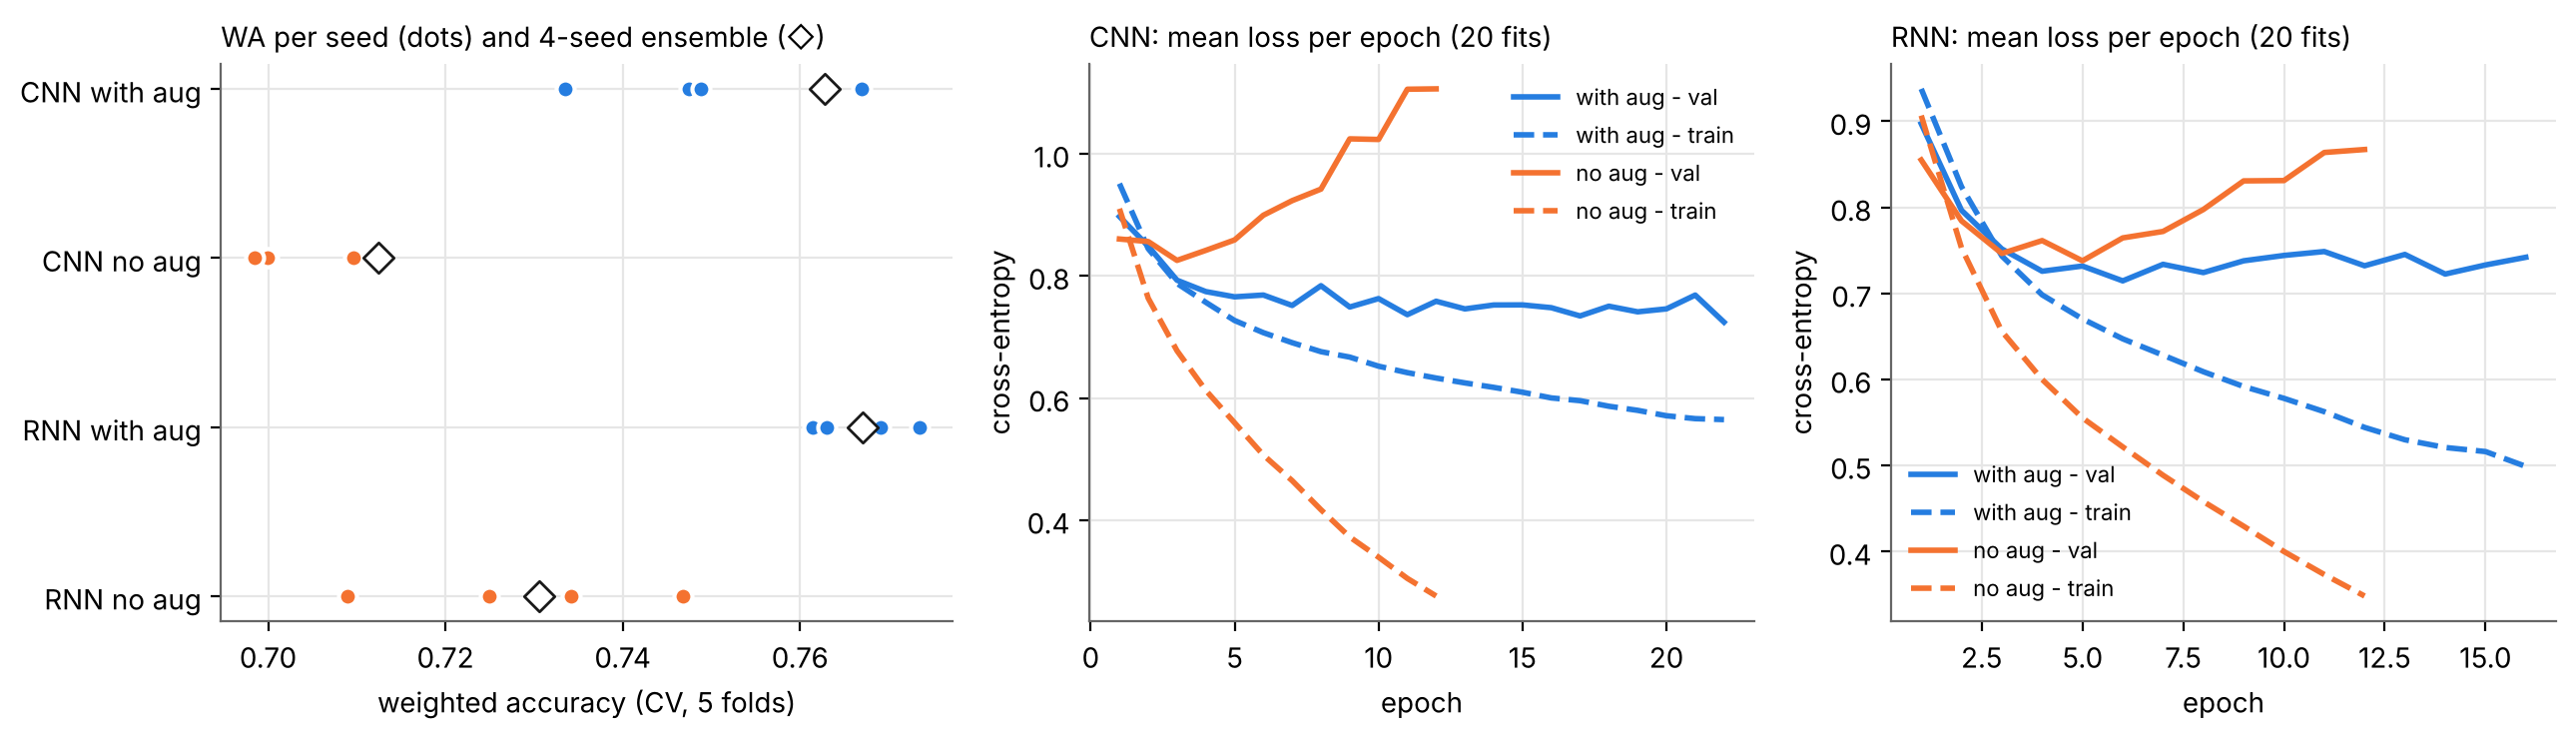

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ylab = ['CNN with aug', 'CNN no aug', 'RNN with aug', 'RNN no aug']
for i, (m, k) in enumerate([('cnn', 'ref'), ('cnn', 'noaug'), ('rnn', 'ref'), ('rnn', 'noaug')]):
    c = BLUE if k == 'ref' else ORANGE
    v = [RUN[n]['wa_mean'] for n in group(m, k)]
    ax[0].scatter(v, [i] * 4, s=42, color=c, edgecolor='white', linewidth=1.5, zorder=3)
    ax[0].scatter(ENS[(m, k)]['wa_mean'], i, marker='D', s=60, color='white', edgecolor=INK, zorder=4)
ax[0].set_yticks(range(4), ylab); ax[0].invert_yaxis(); ax[0].set_xlabel('weighted accuracy (CV, 5 folds)')
ax[0].set_title('WA per seed (dots) and 4-seed ensemble (◇)', loc='left', fontsize=10)
for j, m in enumerate(['cnn', 'rnn']):
    a = ax[j + 1]
    for k, c in [('ref', BLUE), ('noaug', ORANGE)]:
        for col, ls in [('val_loss', '-'), ('train_loss', '--')]:
            cur = pd.concat([d[col].reset_index(drop=True) for d in H[(m, k)]['curve']], axis=1)
            keep = cur.notna().sum(axis=1) >= cur.shape[1] / 2     # epochs reached by at least half of the 20 fits
            a.plot(np.arange(1, keep.sum() + 1), cur[keep].mean(axis=1), ls, color=c, lw=2,
                   label=f"{'with aug' if k == 'ref' else 'no aug'} - {col.split('_')[0]}")
    a.set_title(f'{m.upper()}: mean loss per epoch (20 fits)', loc='left', fontsize=10); a.set_xlabel('epoch')
    a.set_ylabel('cross-entropy'); a.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'augmentation.png', dpi=150); plt.show()

**Finding A — augmentation is clearly useful, for both models.** Without it, every one of the 8 runs is worse
than every reference run of the same model:

- CNN: 0.749 → 0.702 per seed (ensemble 0.763 → 0.712), worse in 5/5 folds; RNN: 0.767 → 0.729 (ensemble 0.767 → 0.731), worse in 5/5 folds.
- The Present AUC also falls (CNN 0.903 → 0.864, RNN 0.928 → 0.908 for the ensembles), so it is not only a threshold effect.
- Why (histories): without augmentation the validation loss is at its minimum after ~3–4 epochs (with it, ~9–12),
  the best validation loss is higher and the train–validation gap at that point roughly doubles (CNN 0.05 → 0.11,
  RNN 0.07 → 0.11). The models memorise the fixed windows quickly; random crops and masks delay that.

The augmentation stays on in the final model.

## B. Demographics (age + height): from the start vs at the end

Like-for-like comparison: every row below is a **4-seed ensemble of the same audio models** evaluated in the same
way, so the only difference is how the demographics enter.

- *early fusion*: the 4 `*_demo` runs (wide branch: 6 demographic inputs → 16 units, concatenated before the classifier);
- *stacking*: multinomial logistic regression on the logits of the reference ensemble (+ age / height), nested CV
  (`src/stacking.py`, numbers from `stack_<model>/stacking_summary.json`; the stacking `base` row is the same
  ensemble as the reference, 0.763 / 0.767, as it should be).

In [6]:
rows = []
for m in ['cnn', 'rnn']:
    ref_f = ENS[(m, 'ref')]['wa_folds']
    st = json.loads((RESULTS_DIR / f'stack_{m}' / 'stacking_summary.json').read_text())['variants']
    assert abs(st['base']['wa_mean'] - ENS[(m, 'ref')]['wa_mean']) < 1e-6
    cand = [('audio only (reference)', ENS[(m, 'ref')]['wa_folds'], ENS[(m, 'ref')]),
            ('early fusion: --demo age height', ENS[(m, 'demo')]['wa_folds'], ENS[(m, 'demo')])]
    for v, lab in [('meta_audio', 'stacking: LR on audio only'), ('meta_age', 'stacking: + age'),
                   ('meta_age_height', 'stacking: + age + height')]:
        s = st[v]
        cand.append((lab, np.array(s['wa_per_fold']), {'wa_mean': s['wa_mean'], 'recall': s['recall'],
                                                        'auc_present': s['auc']['Present'], 'auc_unknown': s['auc']['Unknown']}))
    for lab, f, r in cand:
        gain = r['wa_mean'] - ENS[(m, 'ref')]['wa_mean']
        rows.append({'model': m.upper(), 'variant': lab, 'WA': r['wa_mean'], 'vs audio only': gain,
                     'folds better': int((f > ref_f + 1e-9).sum()), 'adopt?': 'yes' if gain >= .02 and (f > ref_f).sum() >= 4 else 'no',
                     'recall Unknown': r['recall']['Unknown'], 'AUC Present': r['auc_present'], 'AUC Unknown': r['auc_unknown'],
                     '_folds': f})
demo = pd.DataFrame(rows).set_index(['model', 'variant'])
demo.drop(columns='_folds').round(3)

WA  vs audio only  folds better  \
model variant                                                               
CNN   audio only (reference)           0.763          0.000             0   
      early fusion: --demo age height  0.757         -0.006             2   
      stacking: LR on audio only       0.727         -0.036             0   
      stacking: + age                  0.751         -0.012             1   
      stacking: + age + height         0.740         -0.022             1   
RNN   audio only (reference)           0.767          0.000             0   
      early fusion: --demo age height  0.767         -0.000             2   
      stacking: LR on audio only       0.768          0.001             4   
      stacking: + age                  0.770          0.003             2   
      stacking: + age + height         0.769          0.002             4   

                                      adopt?  recall Unknown  AUC Present  \
model variant                                                               
CNN   audio only (reference)              no           0.278        0.903   
      early fusion: --demo age height     no           0.185        0.902   
      stacking: LR on audio only          no           0.148        0.895   
      stacking: + age                     no           0.185        0.893   
      stacking: + age + height            no           0.167        0.890   
RNN   audio only (reference)              no           0.185        0.928   
      early fusion: --demo age height     no           0.259        0.917   
      stacking: LR on audio only          no           0.204        0.924   
      stacking: + age                     no           0.148        0.921   
      stacking: + age + height            no           0.111        0.917   

                                       AUC Unknown  
model variant                                       
CNN   audio only (reference)                 0.795  
      early fusion: --demo age height        0.800  
      stacking: LR on audio only             0.789  
      stacking: + age                        0.781  
      stacking: + age + height               0.778  
RNN   audio only (reference)                 0.788  
      early fusion: --demo age height        0.785  
      stacking: LR on audio only             0.785  
      stacking: + age                        0.781  
      stacking: + age + height               0.775

In [7]:
seed = pd.DataFrame({f'{m.upper()} {k}': [RUN[n]['wa_mean'] for n in group(m, k)] for m in ['cnn', 'rnn'] for k in ['ref', 'demo']},
                    index=['s42', 's1', 's2', 's3']).T
seed['mean'] = seed.mean(axis=1); print('single models (no ensembling): WA per seed'); seed.round(3)

single models (no ensembling): WA per seed


,s42,s1,s2,s3,mean
CNN ref,0.767,0.734,0.748,0.749,0.749
CNN demo,0.727,0.743,0.754,0.757,0.746
RNN ref,0.761,0.763,0.773,0.769,0.767
RNN demo,0.747,0.768,0.779,0.775,0.767


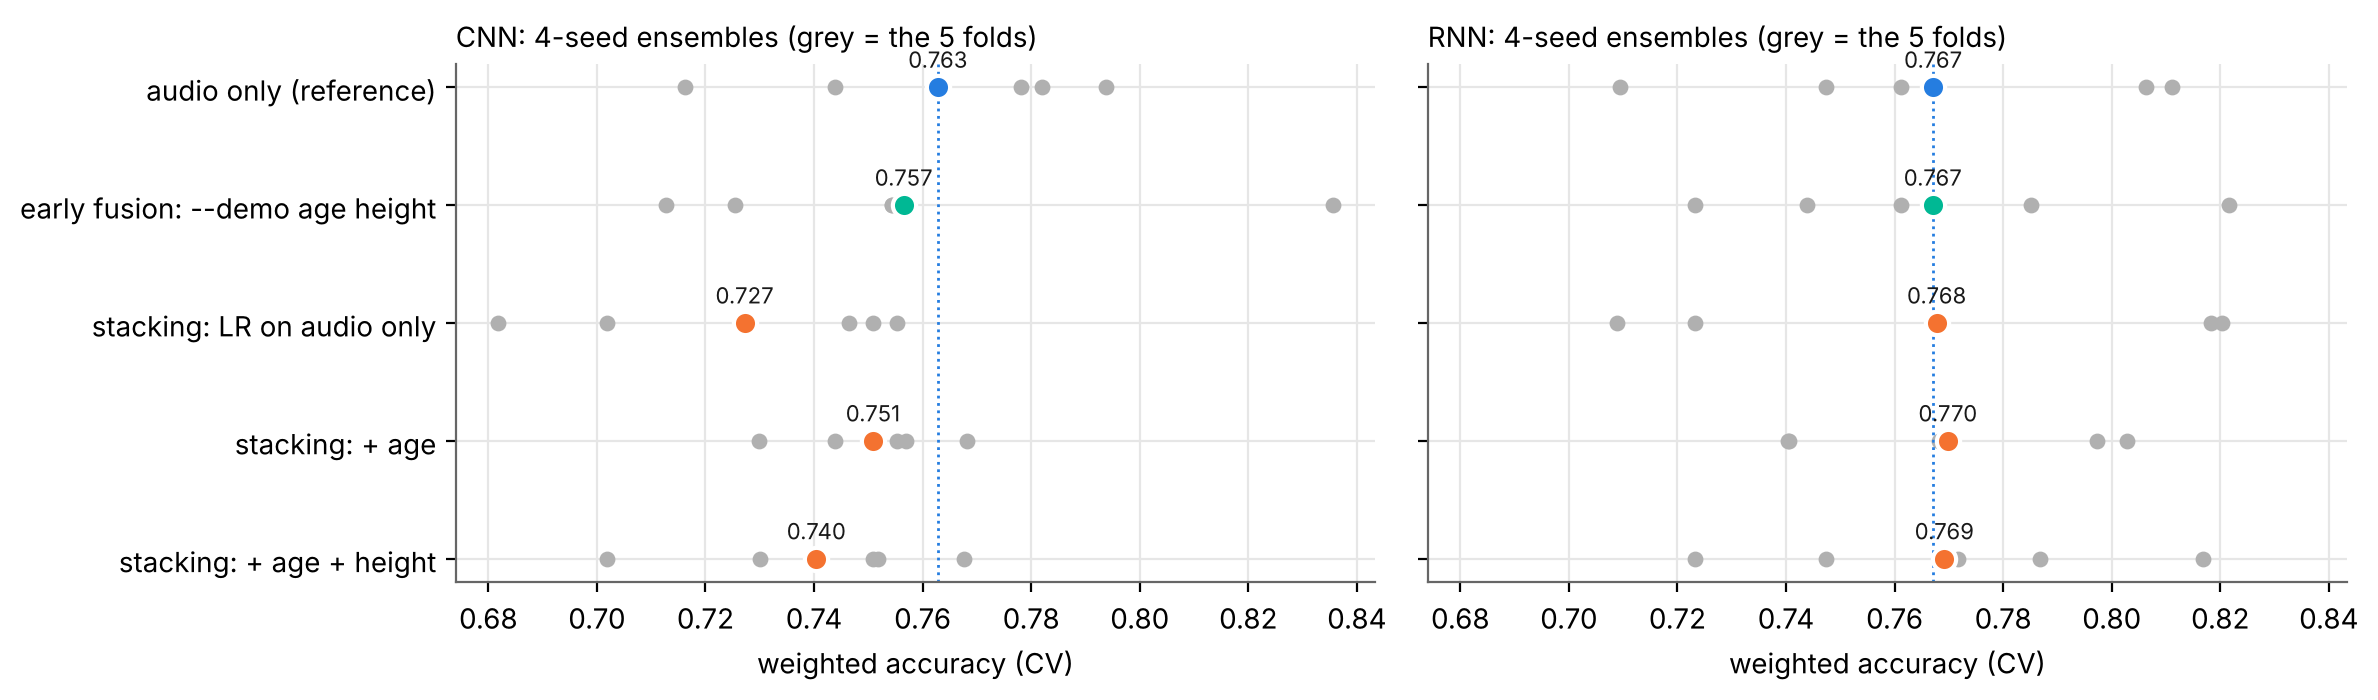

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for a, m in zip(ax, ['CNN', 'RNN']):
    d = demo.loc[m]
    for i, (lab, r) in enumerate(d.iterrows()):
        a.scatter(r['_folds'], [i] * 5, s=22, color=GREY, zorder=2)
        a.scatter(r['WA'], i, s=70, color=BLUE if i == 0 else AQUA if i == 1 else ORANGE, edgecolor='white', lw=1.5, zorder=3)
        a.annotate(f"{r['WA']:.3f}", (r['WA'], i), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8, color=INK)
    a.axvline(d['WA'].iloc[0], color=BLUE, lw=1, ls=':')
    a.set_yticks(range(len(d)), d.index); a.invert_yaxis(); a.set_title(f'{m}: 4-seed ensembles (grey = the 5 folds)', loc='left', fontsize=10)
    a.set_xlabel('weighted accuracy (CV)')
ax[1].set_yticklabels([])
fig.tight_layout(); fig.savefig(FIG / 'demographics.png', dpi=150); plt.show()

**Finding B — neither way of adding age + height passes the adoption rule; nothing to adopt.**

- **Early fusion.** CNN ensemble 0.757 vs 0.763 (−0.006, better in 2/5 folds); RNN 0.767 vs 0.767 (+0.000, 2/5).
  Single models: CNN 0.746 vs 0.749, RNN 0.767 vs 0.767 per seed. Recall of *Unknown* does not improve consistently
  (CNN 0.19 vs 0.28, RNN 0.26 vs 0.19), which was the reason to try age.
- **Stacking.** For the CNN the logistic regression itself costs 0.036 WA (0.727 vs 0.763 with audio only); adding age
  recovers part of it (0.751, adopted *vs the LR on audio*, which is the comparison `stacking.py` prints), but it
  stays below the plain ensemble. For the RNN the three stacking variants are within +0.003 of the ensemble
  (best: + age, 0.770, better in 2/5 folds).
- Early vs late, same-type numbers: CNN 0.757 (early) vs 0.751 / 0.740 (stacking + age / + age + height);
  RNN 0.767 vs 0.770 / 0.769. Differences of ≤ 0.01 between them, all inside the fold-to-fold spread (sd ≈ 0.04).

Why so little effect, given the strong association of age with *Unknown* (01_eda §10)? The next cell checks it.

In [9]:
ps = [load_oof(n) for n in group('rnn', 'ref')]
pat = patient_scores(windows.loc[ps[0][0]], np.mean([p for _, p in ps], axis=0))
age = pd.read_csv('data/circor/training_data.csv').set_index('Patient ID')['Age'].fillna('missing')
pat['age'] = pat.index.map(age)
is_u = pat['murmur'] == 'Unknown'
rate = is_u.groupby(pat['age']).mean()                  # share of Unknown per age group
print('AUC for Unknown: age group alone %.3f | audio P(Unknown) %.3f' % (
      roc_auc_score(is_u, pat['age'].map(rate)), roc_auc_score(is_u, pat['Unknown'])))
pd.DataFrame({'patients': pat['age'].value_counts(), 'Unknown (%)': 100 * rate,
              'mean audio P(Unknown)': pat.groupby('age')['Unknown'].mean()}).round(2)

AUC for Unknown: age group alone 0.645 | audio P(Unknown) 0.788


,patients,Unknown (%),mean audio P(Unknown)
age,,,
Adolescent,65,4.62,0.29
Child,524,5.53,0.32
Infant,99,20.20,0.49
Neonate,4,0.00,0.38
missing,61,3.28,0.32


**Reading.** Age alone separates *Unknown* worse than the audio (AUC 0.645 vs 0.788), and the audio model, which
never sees the age, already gives infants a much higher P(Unknown) (0.49 vs 0.32 for children): an *Unknown* in an
infant is crying and movement noise, which is audible. Age is a proxy for something the network already hears, so it
adds little new information; with only 20 infant *Unknown* patients in CV, the possible gain in WA is small.

## C. Candidates for the hidden-set model

In [10]:
cands = {'RNN 4 seeds (audio)': group('rnn', 'ref'), 'CNN 4 seeds (audio)': group('cnn', 'ref'),
         'CNN + RNN (audio, 8 runs)': group('cnn', 'ref') + group('rnn', 'ref'),
         'RNN demo 4 seeds': group('rnn', 'demo'),
         'CNN demo + RNN demo (8 runs)': group('cnn', 'demo') + group('rnn', 'demo')}
C = {k: ensemble(v) for k, v in cands.items()}
ref_f = C['RNN 4 seeds (audio)']['wa_folds']
final = pd.DataFrame({k: {'WA': r['wa_mean'], 'sd folds': r['wa_std'], 'vs RNN audio': r['wa_mean'] - C['RNN 4 seeds (audio)']['wa_mean'],
                          'folds better': int((r['wa_folds'] > ref_f).sum()), 'recall P': r['recall']['Present'],
                          'recall U': r['recall']['Unknown'], 'recall A': r['recall']['Absent'],
                          'AUC P': r['auc_present'], 'AUC U': r['auc_unknown']} for k, r in C.items()}).T
final.round(3)

,WA,sd folds,vs RNN audio,folds better,recall P,recall U,recall A,AUC P,AUC U
RNN 4 seeds (audio),0.767,0.043,0.000,0.0,0.832,0.185,0.853,0.928,0.788
CNN 4 seeds (audio),0.763,0.032,-0.004,2.0,0.790,0.278,0.869,0.903,0.795
"CNN + RNN (audio, 8 runs)",0.767,0.041,-0.000,1.0,0.818,0.278,0.844,0.923,0.800
RNN demo 4 seeds,0.767,0.038,-0.000,2.0,0.790,0.259,0.885,0.917,0.785
CNN demo + RNN demo (8 runs),0.783,0.040,0.016,4.0,0.832,0.241,0.878,0.914,0.803


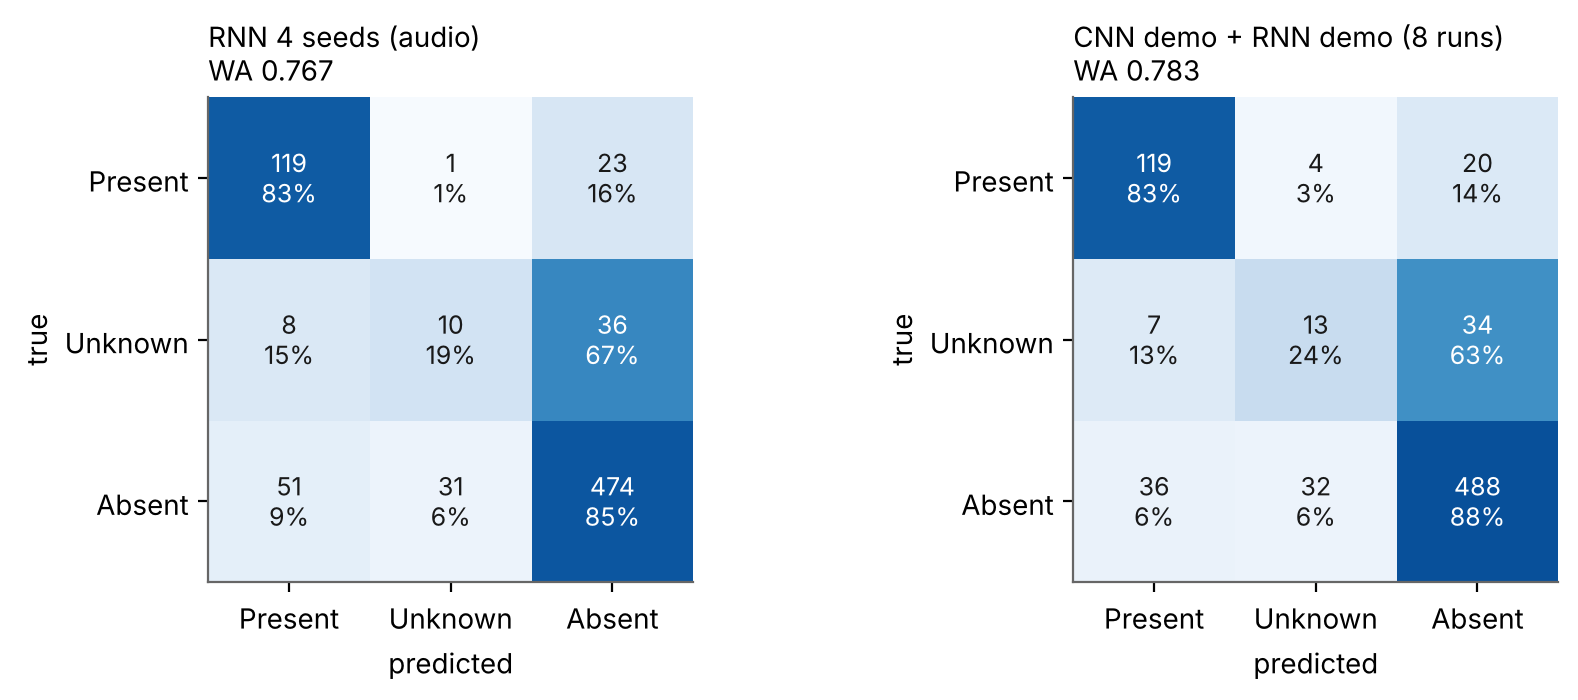

In [11]:
from src.evaluate import cv_report
def confusion(names):
    ps = [load_oof(n) for n in names]
    _, _, rep = cv_report(patient_scores(windows.loc[ps[0][0]], np.mean([p for _, p in ps], 0)))
    return rep['confusion'].T  # rows = true class, columns = predicted

show = ['RNN 4 seeds (audio)', 'CNN demo + RNN demo (8 runs)']
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, k in zip(ax, show):
    m = confusion(cands[k]); a.imshow(m / m.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            frac = m[i, j] / m[i].sum()
            a.text(j, i, f'{m[i, j]}\n{frac:.0%}', ha='center', va='center', fontsize=9, color='white' if frac > .55 else INK)
    a.set_xticks(range(3), CLASSES); a.set_yticks(range(3), CLASSES); a.grid(False)
    a.set_xlabel('predicted'); a.set_ylabel('true'); a.set_title(f"{k}\nWA {C[k]['wa_mean']:.3f}", loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'final_confusion.png', dpi=150); plt.show()

**Finding C — choice of the final model.**

- By the rule fixed before the experiments, **no change is adopted**: final model = RNN, audio only, augmentation on,
  4 seeds, no stacking. It has the best Present AUC (0.928), the smallest seed spread (sd 0.006) and is the simplest
  model. The CNN + RNN ensemble gives the same WA (0.767), so mixing models does not pay for the extra cost.
- The only combination that looks better is CNN demo + RNN demo (0.783, +0.016, better in 4/5 folds). It fails the
  rule (gain < 0.02) and was found after comparing several combinations on the same folds, so part of the gain is
  selection. It is reported as an observation, not used.
- Caveats: each fold has ~150 patients (sd of WA across folds ≈ 0.04), so differences below ~0.02 are not
  distinguishable from noise; *Unknown* (54 patients in CV) remains the weak point of every variant (recall ≤ 0.35).

## D. Submitted model: RNN retrained with the test fold

`bash scripts/submit_final.sh rnn`: the same RNN, 4 seeds, with the 189 test patients added to the training set of
every fold (`--include-test`). Early stopping and thresholds still use the 5 CV folds, so the CV numbers below are
computed as before (the test fold can no longer be used to evaluate these runs). The hidden-set prediction averages
the 20 fold models and uses the thresholds tuned on the averaged out-of-fold predictions.

In [12]:
final_runs = [f'rnn_final_s{s}' for s in [42, 1, 2, 3]]
cfgs = [json.loads((RESULTS_DIR / n / 'cv_summary.json').read_text())['cfg'] for n in final_runs]
assert all(c['include_test'] and c['spec_augment'] and c['random_crop'] and not c['demo_features'] for c in cfgs)
fin = ensemble(final_runs)
print('WA per seed:', ' '.join(f"{evaluate(windows, *load_oof(n))['wa_mean']:.3f}" for n in final_runs))
print(f"ensemble: WA {fin['wa_mean']:.3f} ± {fin['wa_std']:.3f} | recall",
      {k: round(v, 2) for k, v in fin['recall'].items()}, f"| AUC Present {fin['auc_present']:.3f}")

ps = [load_oof(n) for n in final_runs]
pat_f = patient_scores(windows.loc[ps[0][0]], np.mean([p for _, p in ps], axis=0))
t, _ = tune_thresholds(pat_f)
info = json.loads(Path('submission/PL3_G08_test_results_info.json').read_text())
print('thresholds tuned here:', t, '| used for the submission:', tuple(info['thresholds']))

sub = pd.read_csv('submission/PL3_G08_test_results.csv', dtype={'ID': str})
tpl = pd.read_csv('data/hidden/CirCor_test_students/PLX_GYY_test_results.csv', dtype={'ID': str})
assert list(sub.columns) == list(tpl.columns) and sub['ID'].tolist() == tpl['ID'].tolist() and sub['Murmur'].notna().all()
pd.DataFrame({'hidden set: predicted (%)': 100 * sub['Murmur'].value_counts(normalize=True),
              'CV: predicted (%)': 100 * pd.Series(cv_report(pat_f)[1]).value_counts(normalize=True),
              'CV: true (%)': 100 * pat_f['murmur'].value_counts(normalize=True)}).reindex(CLASSES).round(1)

WA per seed: 0.767 0.764 0.760 0.755
ensemble: WA 0.771 ± 0.034 | recall {'Present': 0.81, 'Unknown': 0.2, 'Absent': 0.88} | AUC Present 0.931
thresholds tuned here: (0.525, 0.675) | used for the submission: (0.525, 0.675)


,hidden set: predicted (%),CV: predicted (%),CV: true (%)
Present,30.0,18.9,19.0
Unknown,8.0,7.3,7.2
Absent,62.0,73.8,73.8


**Finding D.** The 4 final seeds reach WA 0.755–0.767 each and **0.771 as an ensemble** (reference RNN ensemble
0.767: the extra 189 training patients do not change the CV performance noticeably). The submission uses the
thresholds tuned on the averaged out-of-fold predictions (0.525, 0.675), and the CSV follows the template (100
patients, same order).

On the hidden set the model predicts **30 % *Present***, against 19 % predicted (and 19 % true) in CV. The hidden
patients are all from campaign CC2015, where 21 % of the training patients are *Present*, so part of the gap is the
campaign and part is sampling (100 patients: ±4 % standard error); the rest are likely extra *Present* alarms. With
the metric weights a false *Present* costs much less than a missed one, so we keep the thresholds chosen in CV.

Figures for the slides: `results/final_experiments/augmentation.png`, `demographics.png`, `final_confusion.png`.